# 233. Botryllus matches to human immune genes and HLA, with all 19 kmerseek alphabets at matched bits

**Question.** [Notebook 232](232_kmerseek_botryllus_vs_human_immune_genes_hla.ipynb) searched
with one alphabet (`hp_lehninger2`, k = 24) and found no Botryllus protein matching an HLA gene
below E = 0.1. Does any other kmerseek alphabet find a Botryllus protein that matches a human
immune gene, and HLA in particular, at E ≤ 10, when every alphabet gets k-mers carrying the
same information?

**Decision this informs.** Which Botryllus proteins go forward as MHC-like candidates for
structure comparison, and whether the "no HLA match" result of notebook 232 depends on the
alphabet.

**Decision rule, written before looking at the results** (the same as notebook 232's).

* A Botryllus protein is an MHC-like candidate if, in any alphabet, it matches an HLA gene at
  E ≤ 0.001 and the matched part of the HLA protein is the peptide-binding groove (class I
  α1/α2, class II α1/β1) or the Ig-like domain.
* HLA matches with E between 0.001 and 10 are listed but treated as chance. A match found
  by several alphabets is listed with the number of alphabets that find it, but agreement
  between alphabets is not evidence on its own: the alphabets read the same residues.
* A match only to the HLA transmembrane helix or signal peptide is not MHC evidence.

**Matched information per k-mer.** Each alphabet's k is the smallest k whose k-mers carry
at least the bits of `hp_lehninger2` at k = 24 (24.0 bits). Bits per k-mer = k × the
Shannon entropy of the alphabet's class shares on the human target proteome (not log2 of
the class count: gbmr7 has 7 classes but 2.0 bits per position, because one class holds
most residues). The result is 24.0 to 27.7 bits per k-mer (`233_arms.tsv`, made by
`233_plan_arms.py`).

**Data.**

* Tool: kmerseek 0.4.0 (the release notebook 232 used), scaled = 1, low-complexity k-mers
  removed. Each alphabet's extension uses its own mismatch penalty and X-drop, the values
  notebook 241 of seanome/2024-kmerseek-analysis ran with. hp_lehninger2 therefore uses
  penalty 1.51 here against 1.63 in notebook 232.
* Query: 72,617 Botryllus protein translations (`Bs_proteins.fa`).
* Target database: 19,429 human GENCODE v49 canonical proteins.
* Run: Sherlock array 49626308 (26 Oct 2026), `233_kmerseek_alphabets.sbatch` and
  `233_kmerseek_alphabet_arm.py`. A match is kept by kmerseek when the whole-query p-value
  is below 0.05 or the best region's score is at least 1.3, the filters of notebook 232.
  Then only matches with E ≤ 10 or E = inf are kept, and only those to human immune genes
  (`233_filter_immune.sbatch`).
* Human immune genes: QuickGO GO:0002376 "immune system process" and the terms below it,
  the list of notebook 232. HLA protein parts come from UniProt (`hla_utils.py`).
* E = inf: kmerseek found shared k-mers but did not extend them into an alignment, so no
  E-value exists. For three alphabets these are hundreds of millions of matches; they are
  summarised on Sherlock (`233_summarise_inf.sbatch`) and reported in section 5.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import pubfig as pf
from hla_utils import (CLASS_I, KNOWN_IMMUNE_FAMILY_PATTERN, PART_COLOUR, PART_MARKER, HlaParts,
                       load_immune_genes, with_gene_columns)

pf.use_style()
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(60)

RUN_DIR = Path.home() / "data/botryllus/kmerseek-0.4-alphabets"
TOOL_LINE = "kmerseek 0.4.0, 19 alphabets at ≥ 24 bits per k-mer, scaled = 1, low-complexity k-mers removed"
QUERY_TARGET_LINE = "query: Botryllus proteins (72,617); target: human GENCODE v49 canonical (19,429)"
MAX_EVALUE = 10
STRICT_EVALUE = 1e-3
EVALUE_CUTOFFS = [10, 1, STRICT_EVALUE]
ZERO_X = 0.5  # where a count of 0 is drawn on a log axis, as a grey x
N_PAIRS = 72_617 * 19_429  # Botryllus proteins x human proteins: tests per alphabet
OUT_DIR = Path("233_outputs")
FIG_DIR = Path("../figures/233")
for d in (OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

arms = pl.read_csv("233_arms.tsv", separator="\t")
# Alphabets grouped by class count, with a gap between groups on every figure.
GROUPS = [("2-3 classes", 2, 3), ("4-8 classes", 4, 8), ("12-18 classes", 12, 18), ("20 classes", 20, 20)]
arms = arms.with_columns(
    pl.when(pl.col("n_classes") <= 3).then(0).when(pl.col("n_classes") <= 8).then(1)
    .when(pl.col("n_classes") <= 18).then(2).otherwise(3).alias("group")
).sort("group", "n_classes", "alphabet")
ALPHABETS = arms["alphabet"].to_list()
K_OF = dict(zip(arms["alphabet"], arms["ksize"]))
Y_OF, y = {}, 0
for g in range(len(GROUPS)):
    for a in arms.filter(pl.col("group") == g)["alphabet"]:
        Y_OF[a] = y
        y += 1
    y += 0.8  # gap between groups
LABEL_OF = {a: f"{a}, k = {K_OF[a]}" for a in ALPHABETS}


def tag(alphabet: str) -> str:
    return f"{alphabet}.k{K_OF[alphabet]}.scaled1.lcremoved"


def alphabet_axis(ax) -> None:
    """One row per alphabet, grouped by class count, a guide line from each tick."""
    ax.set_yticks([Y_OF[a] for a in ALPHABETS], [LABEL_OF[a] for a in ALPHABETS])
    for a in ALPHABETS:
        ax.axhline(Y_OF[a], color="#dddddd", linewidth=0.3, zorder=0)
    ax.set_ylim(max(Y_OF.values()) + 0.6, -0.6)


immune_genes = load_immune_genes()
print(f"{len(ALPHABETS)} alphabets, {len(immune_genes):_} human immune gene symbols")
print(arms.drop("group"))

19 alphabets, 2_634 human immune gene symbols
shape: (19, 7)
┌──────────────────────────┬───────────┬───────────────────┬───────┬───────────────┬─────────┬───────┐
│ alphabet                 ┆ n_classes ┆ bits_per_position ┆ ksize ┆ bits_per_kmer ┆ penalty ┆ xdrop │
│ ---                      ┆ ---       ┆ ---               ┆ ---   ┆ ---           ┆ ---     ┆ ---   │
│ str                      ┆ i64       ┆ f64               ┆ i64   ┆ f64           ┆ f64     ┆ f64   │
╞══════════════════════════╪═══════════╪═══════════════════╪═══════╪═══════════════╪═════════╪═══════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ 0.937             ┆ 26    ┆ 24.36         ┆ 1.57    ┆ 6.28  │
│ hp_lehninger2            ┆ 2         ┆ 1.0               ┆ 24    ┆ 24.0          ┆ 1.51    ┆ 6.03  │
│ hp_lehninger_c_nonpolar2 ┆ 2         ┆ 0.9988            ┆ 25    ┆ 24.97         ┆ 1.52    ┆ 6.08  │
│ hp_pbotc_1st_ed2         ┆ 2         ┆ 0.9941            ┆ 25    ┆ 24.85         ┆ 1.59    ┆ 6.35  │
│ hp_thomas_

## 1. The 19 runs: E-value fits, run time, and how many matches kmerseek did not extend

In [2]:
runs = []
for a in ALPHABETS:
    s = json.loads((RUN_DIR / "evalue_le_10" / f"{tag(a)}.summary.json").read_text())
    runs.append({
        "alphabet": a, "n_classes": s["n_classes"], "ksize": int(s["ksize"]), "bits_per_kmer": float(s["bits_per_kmer"]),
        "fit_first_try": s["fitted_first"], "fitted": s["fitted"],
        "search_minutes": round(s["search_s"] / 60, 1),
        "n_matches": s["n_matches"], "n_evalue_le_10": s["n_evalue_le_10_or_inf"] - s["n_evalue_inf"],
        "n_evalue_inf": s["n_evalue_inf"],
    })
runs = pl.DataFrame(runs).with_columns(
    (pl.col("n_evalue_inf") / (pl.col("n_evalue_le_10") + pl.col("n_evalue_inf"))).alias("fraction_inf"))
# kmerseek's own fit log warns when the fit has few score bins; read it for every alphabet
few_bins = {a: "WARNING: the fit has only" in (RUN_DIR / "logs" / f"{tag(a)}.index.log").read_text() for a in ALPHABETS}
runs = runs.with_columns(pl.col("alphabet").replace_strict(few_bins).alias("fit_warning_few_bins"))
runs.write_csv(OUT_DIR / "233_runs_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
print(runs)

shape: (19, 12)
┌──────────────────────────┬───────────┬───────┬───────────────┬───┬────────────────┬──────────────┬──────────────┬──────────────────────┐
│ alphabet                 ┆ n_classes ┆ ksize ┆ bits_per_kmer ┆ … ┆ n_evalue_le_10 ┆ n_evalue_inf ┆ fraction_inf ┆ fit_warning_few_bins │
│ ---                      ┆ ---       ┆ ---   ┆ ---           ┆   ┆ ---            ┆ ---          ┆ ---          ┆ ---                  │
│ str                      ┆ str       ┆ i64   ┆ f64           ┆   ┆ i64            ┆ i64          ┆ f64          ┆ bool                 │
╞══════════════════════════╪═══════════╪═══════╪═══════════════╪═══╪════════════════╪══════════════╪══════════════╪══════════════════════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ 26    ┆ 24.36         ┆ … ┆ 7186           ┆ 6476197      ┆ 0.998892     ┆ false                │
│ hp_lehninger2            ┆ 2         ┆ 24    ┆ 24.0          ┆ … ┆ 389821         ┆ 14855        ┆ 0.036708     ┆ false                │
│ hp_lehnin

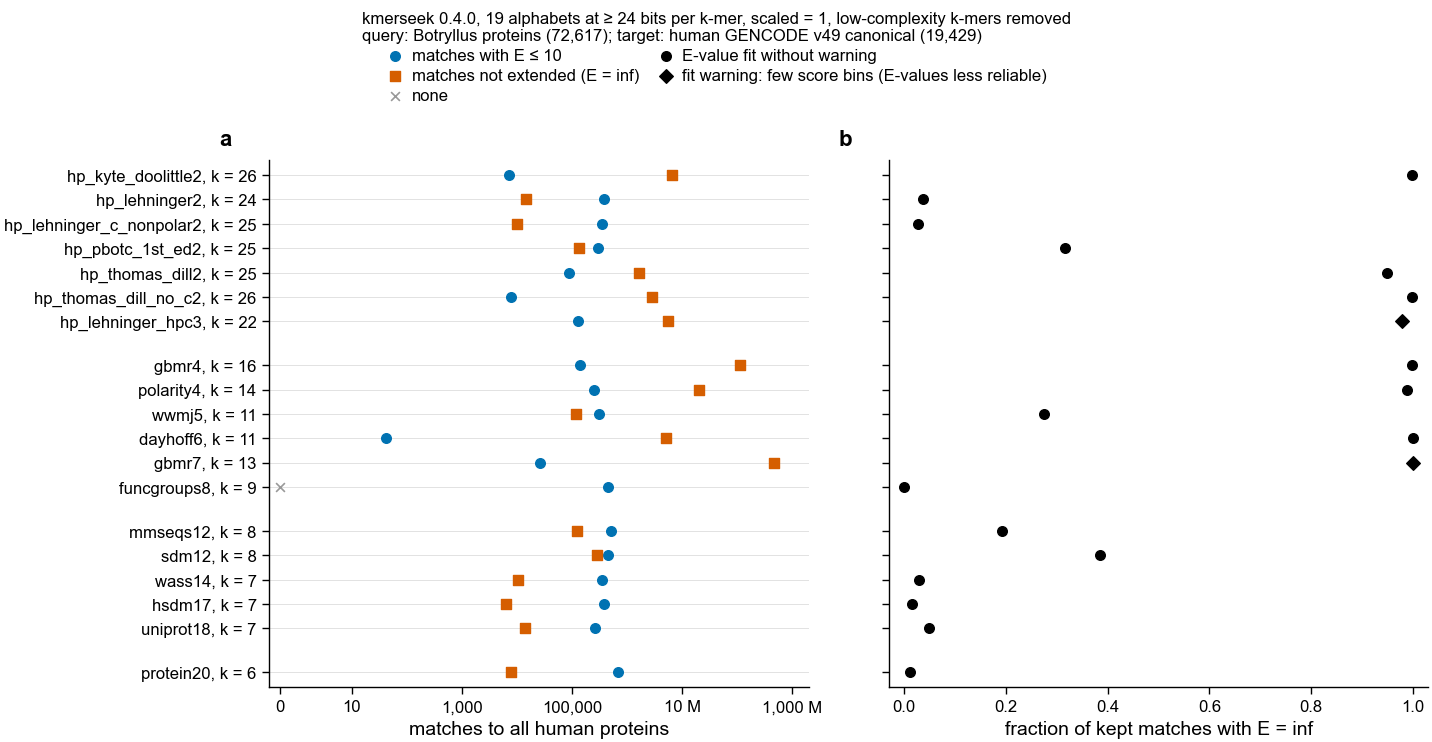

In [3]:
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for a in ALPHABETS:
    r = runs.filter(pl.col("alphabet") == a).row(0, named=True)
    for n, colour, marker in [(r["n_evalue_le_10"], pf.OKABE_ITO["blue"], "o"),
                              (r["n_evalue_inf"], pf.OKABE_ITO["vermillion"], "s")]:
        if n > 0:
            ax_a.scatter(n, Y_OF[a], color=colour, marker=marker, s=12, zorder=3)
        else:
            ax_a.scatter(ZERO_X, Y_OF[a], color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
    ax_b.scatter(r["fraction_inf"], Y_OF[a], color="black", s=12, zorder=3,
                 marker="o" if not r["fit_warning_few_bins"] else "D")
ax_a.scatter([], [], color=pf.OKABE_ITO["blue"], s=12, label="matches with E ≤ 10")
ax_a.scatter([], [], color=pf.OKABE_ITO["vermillion"], marker="s", s=12, label="matches not extended (E = inf)")
ax_a.scatter([], [], color=pf.GREY, marker="x", s=10, linewidths=0.6, label="none")
ax_b.scatter([], [], color="black", s=12, label="E-value fit without warning")
ax_b.scatter([], [], color="black", marker="D", s=12, label="fit warning: few score bins (E-values less reliable)")
ax_a.set_xscale("log")
ax_a.set_xlim(ZERO_X / 1.6, 2e9)
ax_a.set_xticks([ZERO_X, 10, 1e3, 1e5, 1e7, 1e9], ["0", "10", "1,000", "100,000", "10 M", "1,000 M"])
ax_a.set_xlabel("matches to all human proteins")
ax_b.set_xlim(-0.03, 1.03)
ax_b.set_xlabel("fraction of kept matches with E = inf")
alphabet_axis(ax_a)
pf.shared_legend(fig, ncol=2, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip((ax_a, ax_b), "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "233a_runs_matches_extended_vs_not_kmerseek_botryllus_vs_gencode_19_alphabets")
plt.show()

How to read it: each row is one alphabet at its bit-matched k, grouped by number of classes.
Panel a counts kept matches to all human proteins; panel b is the share kmerseek did not
extend. An alphabet whose matches are mostly unextended gives few E-values to compare.

## 2. Botryllus proteins matching human immune genes and HLA, per alphabet

Counts at E ≤ 10 (the question as asked), E ≤ 1 and E ≤ 0.001 (the candidate cut-off).
Only matches with a finite E-value count here.

In [4]:
COLUMNS = ["query_name", "target_name", "region_evalue", "region_ka_bits", "region_tail_probability",
           "region_length", "region_n_shared_kmers", "region_start", "region_end", "target_start",
           "target_end", "region_subseq", "target_subseq"]
frames = []
for a in ALPHABETS:
    path = RUN_DIR / "immune" / f"{tag(a)}.immune.evalue_le_10.csv.gz"
    df = pl.read_csv(path, columns=COLUMNS, infer_schema_length=10_000,
                     schema_overrides={"region_evalue": pl.Float64, "region_tail_probability": pl.Float64})
    frames.append(with_gene_columns(df).with_columns(pl.lit(a).alias("alphabet")))
immune = pl.concat(frames).with_columns(pl.col("human_gene").str.starts_with("HLA-").alias("is_hla"))
assert immune["region_evalue"].is_finite().all() and (immune["region_evalue"] <= MAX_EVALUE).all()
assert immune["human_gene"].is_in(immune_genes).all()

rows = []
for a in ALPHABETS:
    sub = immune.filter(pl.col("alphabet") == a)
    for gene_set, s in [("all immune genes", sub), ("HLA genes", sub.filter("is_hla"))]:
        for cutoff in EVALUE_CUTOFFS:
            hit = s.filter(pl.col("region_evalue") <= cutoff)
            rows.append({"alphabet": a, "gene_set": gene_set, "max_evalue": cutoff, "n_matches": len(hit),
                         "n_botryllus_proteins": hit["query_name"].n_unique(),
                         "n_human_genes": hit["human_gene"].n_unique()})
counts = pl.DataFrame(rows)
counts.write_csv(OUT_DIR / "233_immune_hla_counts_by_evalue_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
print(counts.pivot(on=["gene_set", "max_evalue"], index="alphabet", values="n_botryllus_proteins"))

shape: (19, 7)
┌──────────────────────────┬───────────────────────────┬──────────────────────────┬────────────────────────────┬────────────────────┬───────────────────┬─────────────────────┐
│ alphabet                 ┆ {"all immune genes",10.0} ┆ {"all immune genes",1.0} ┆ {"all immune genes",0.001} ┆ {"HLA genes",10.0} ┆ {"HLA genes",1.0} ┆ {"HLA genes",0.001} │
│ ---                      ┆ ---                       ┆ ---                      ┆ ---                        ┆ ---                ┆ ---               ┆ ---                 │
│ str                      ┆ i64                       ┆ i64                      ┆ i64                        ┆ i64                ┆ i64               ┆ i64                 │
╞══════════════════════════╪═══════════════════════════╪══════════════════════════╪════════════════════════════╪════════════════════╪═══════════════════╪═════════════════════╡
│ hp_kyte_doolittle2       ┆ 389                       ┆ 180                      ┆ 29                   

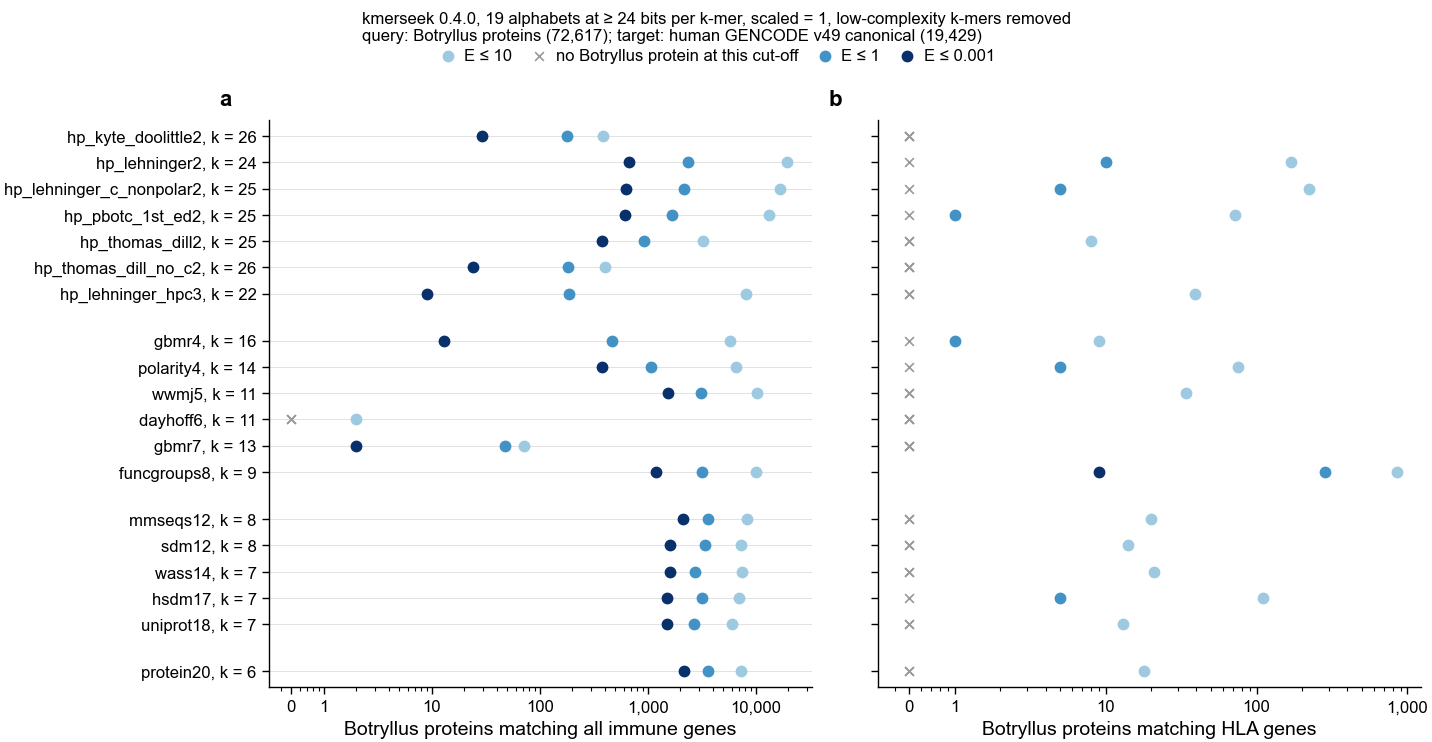

In [5]:
CUTOFF_STYLE = {10: ("#9ecae1", "E ≤ 10"), 1: ("#4292c6", "E ≤ 1"), STRICT_EVALUE: ("#08306b", "E ≤ 0.001")}

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for ax, gene_set in zip(axs, ["all immune genes", "HLA genes"]):
    for cutoff, (colour, label) in CUTOFF_STYLE.items():
        sub = counts.filter((pl.col("gene_set") == gene_set) & (pl.col("max_evalue") == cutoff))
        ys = [Y_OF[a] for a in sub["alphabet"]]
        n = sub["n_botryllus_proteins"].to_numpy()
        ax.scatter(np.where(n > 0, n, np.nan), ys, color=colour, s=14, zorder=3, label=label)
        ax.scatter(np.where(n == 0, ZERO_X, np.nan), ys, color=pf.GREY, marker="x", s=10, linewidths=0.6,
                   zorder=2, label="no Botryllus protein at this cut-off")
    ax.set_xscale("log")
    ax.set_xlim(ZERO_X / 1.6, None)
    ticks = [t for t in [1, 10, 100, 1_000, 10_000, 100_000] if t <= max(1, counts.filter(pl.col("gene_set") == gene_set)["n_botryllus_proteins"].max()) * 3]
    ax.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
    ax.set_xlabel(f"Botryllus proteins matching {gene_set}")
alphabet_axis(axs[0])
pf.shared_legend(fig, ncol=4, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "233b_botryllus_proteins_matching_immune_and_hla_by_evalue_kmerseek_19_alphabets")
plt.show()

How to read it: each row is one alphabet; light to dark blue is loose to strict E-value
cut-off. A grey × at 0 means no Botryllus protein passes that cut-off. Panel b is the question
of this notebook: a dark-blue dot in panel b would be an HLA match at the candidate cut-off.

## 3. The HLA matches in every alphabet, and which part of the HLA protein they cover

In [6]:
hla = immune.filter("is_hla")
hla_parts = HlaParts(dict(hla.group_by("human_gene").agg(pl.col("human_protein_length").first()).iter_rows()))
print(hla_parts.length_check)
hla = hla_parts.add_columns(hla)
assert set(hla["hla_part_matched"]) <= set(PART_COLOUR), set(hla["hla_part_matched"])
hla.sort("region_evalue").write_csv(OUT_DIR / "233_hla_matches_evalue_le_10_kmerseek_botryllus_vs_gencode_19_alphabets.csv")

best_hla = (hla.sort("region_evalue").group_by("alphabet", maintain_order=True)
            .agg(pl.len().alias("n_hla_matches"), pl.col("query_name").n_unique().alias("n_botryllus_proteins"),
                 pl.col("region_evalue").first().alias("best_evalue"),
                 pl.col("query_name").first().alias("best_botryllus_protein"),
                 pl.col("human_gene").first().alias("best_hla_gene"),
                 pl.col("hla_part_matched").first().alias("part_matched_by_best")))
best_hla = (arms.select("alphabet", "ksize").join(best_hla, on="alphabet", how="left")
            .with_columns(pl.col("n_hla_matches").fill_null(0), pl.col("n_botryllus_proteins").fill_null(0)))
print(best_hla)
print(f"\nHLA matches at E <= {STRICT_EVALUE} in any alphabet: {hla.filter(pl.col('region_evalue') <= STRICT_EVALUE).height}")
print("\nHLA part covered, all alphabets together:")
print(hla.group_by("hla_part_matched").agg(pl.len().alias("n_matches")).sort("n_matches", descending=True))

shape: (19, 5)
┌────────────┬─────────┬────────────────┬────────────────┬─────────────┐
│ human_gene ┆ uniprot ┆ uniprot_length ┆ gencode_length ┆ same_length │
│ ---        ┆ ---     ┆ ---            ┆ ---            ┆ ---         │
│ str        ┆ str     ┆ i64            ┆ i64            ┆ bool        │
╞════════════╪═════════╪════════════════╪════════════════╪═════════════╡
│ HLA-A      ┆ P04439  ┆ 365            ┆ 365            ┆ true        │
│ HLA-B      ┆ P01889  ┆ 362            ┆ 362            ┆ true        │
│ HLA-C      ┆ P10321  ┆ 366            ┆ 366            ┆ true        │
│ HLA-DMA    ┆ P28067  ┆ 261            ┆ 261            ┆ true        │
│ HLA-DMB    ┆ P28068  ┆ 263            ┆ 263            ┆ true        │
│ HLA-DOA    ┆ P06340  ┆ 250            ┆ 250            ┆ true        │
│ HLA-DOB    ┆ P13765  ┆ 273            ┆ 273            ┆ true        │
│ HLA-DPA1   ┆ P20036  ┆ 260            ┆ 260            ┆ true        │
│ HLA-DPB1   ┆ P04440  ┆ 258        

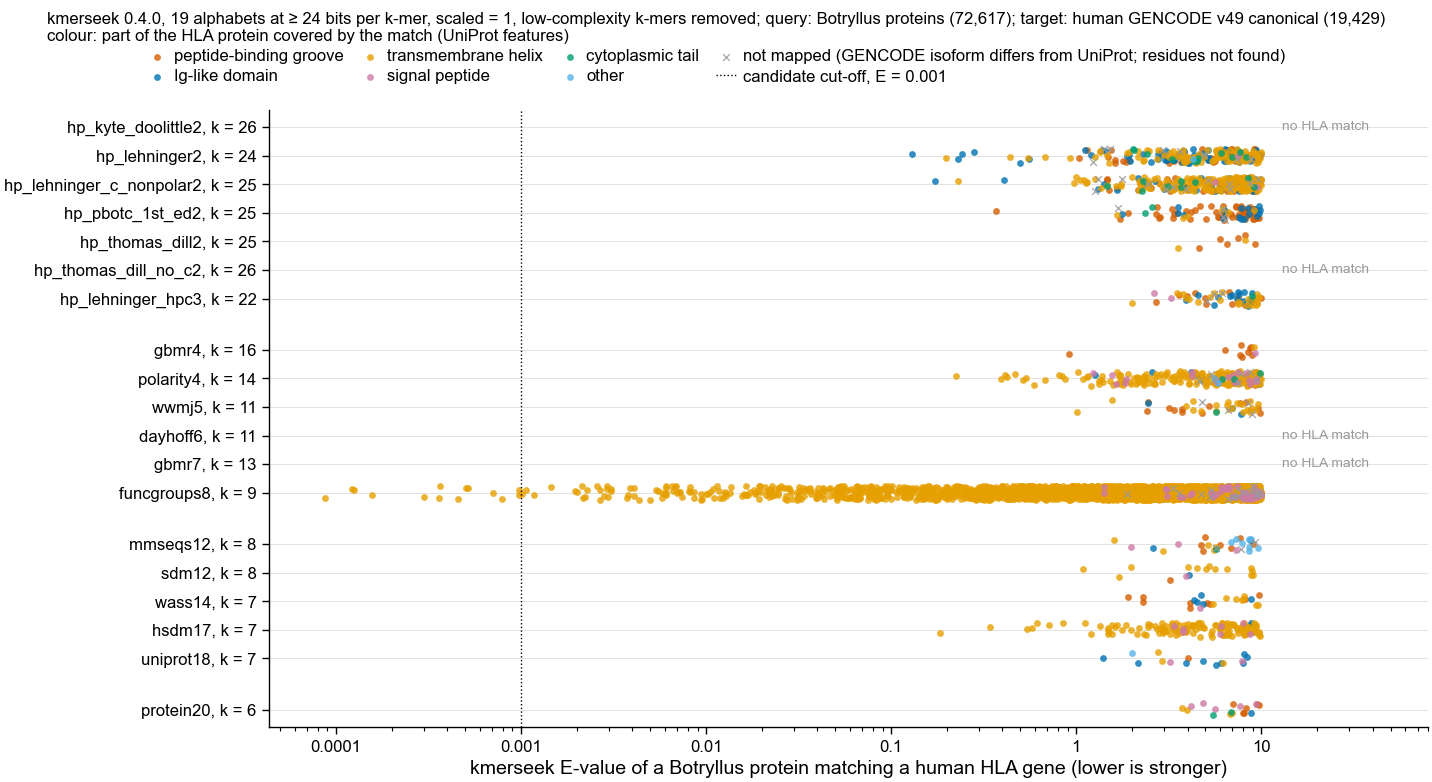

In [7]:
rng = np.random.default_rng(0)
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 100)
for part, colour in PART_COLOUR.items():
    sub = hla.filter(pl.col("hla_part_matched") == part)
    if len(sub) == 0:
        continue
    ys = np.array([Y_OF[a] for a in sub["alphabet"]]) + rng.uniform(-0.25, 0.25, len(sub))
    ax.scatter(sub["region_evalue"], ys, color=colour, s=6, alpha=0.8, marker=PART_MARKER[part],
               linewidths=0 if PART_MARKER[part] == "o" else 0.5, label=part)
for a in ALPHABETS:
    if best_hla.filter(pl.col("alphabet") == a)["n_hla_matches"][0] == 0:
        ax.text(MAX_EVALUE * 1.3, Y_OF[a], "no HLA match", va="center", fontsize=5, color=pf.GREY)
ax.axvline(STRICT_EVALUE, color="black", linewidth=0.5, linestyle=":", label=f"candidate cut-off, E = {STRICT_EVALUE:g}")
ax.set_xscale("log")
left = min(STRICT_EVALUE, hla["region_evalue"].min()) / 2
ax.set_xlim(left, MAX_EVALUE * 8)
ticks = [t for t in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10] if t >= left]
ax.set_xticks(ticks, [f"{t:g}" if t >= 1e-3 else f"{t:.5f}".rstrip("0") for t in ticks])
ax.set_xlabel("kmerseek E-value of a Botryllus protein matching a human HLA gene (lower is stronger)")
alphabet_axis(ax)
pf.shared_legend(fig, ncol=4, title=f"{TOOL_LINE}; {QUERY_TARGET_LINE}\n"
                 "colour: part of the HLA protein covered by the match (UniProt features)")
pf.save(fig, FIG_DIR / "233c_hla_matches_evalue_and_part_kmerseek_botryllus_vs_gencode_19_alphabets")
plt.show()

How to read it: each dot is one Botryllus protein region matched to one HLA protein, in the
row of the alphabet that found it; further left is stronger. A dot left of the dotted line
would meet the candidate rule if its colour is vermillion (groove) or blue (Ig-like).

The best HLA match of each alphabet, in residues (Botryllus first, human second):

In [8]:
best_rows = hla.sort("region_evalue").group_by("alphabet", maintain_order=True).first()
for r in best_rows.sort("region_evalue").iter_rows(named=True):
    print(f"{r['alphabet']:<25} {r['query_name']:<20} vs {r['human_gene']:<9} E = {r['region_evalue']:.3g}  "
          f"human residues {r['target_start'] + 1}-{r['target_end']} ({r['hla_part_matched']})")
    print(f"  Botryllus {r['region_subseq'][:100]}")
    print(f"  human     {r['target_subseq'][:100]}\n")

funcgroups8               g7000.t1 frame:1     vs HLA-DPA1  E = 8.71e-05  human residues 220-244 (transmembrane helix)
  Botryllus TSDTGLIIGVVAALLGIAALASLAV
  human     TTETVLCALGLVLGLVGIIVGTVLI

hp_lehninger2             g564.t1 frame:1      vs HLA-DRA   E = 0.131  human residues 81-158 (Ig-like domain)
  Botryllus MTVIGVQVLAQKVSIRALTCSRRLRLVDQGLLDQSEAVRNVVKTELLQAWLRTYQVLEKLDAIGSYETTRKAVQAMFD
  human     AQGALANIAVDKANLEIMTKRSNYTPITNVPPEVTVLTNSPVELREPNVLICFIDKFTPPVVNVTWLRNGKPVTTGVS

hp_lehninger_c_nonpolar2  g65873.t1 frame:1    vs HLA-B     E = 0.173  human residues 245-338 (Ig-like domain)
  Botryllus PTDYSDSRNGVARIDITNRTPGKLYIVCMMESSKDIADLTIEDCEFVETNSASPGQIHDNEAIVPVWLAILIALLVILVLAAIVLVVYCQRLNA
  human     GEDQTQDTELVETRPAGDRTFQKWAAVVVPSGEEQRYTCHVQHEGLPKPLTLRWEPSSQSTVPIVGIVAGLAVLAVVVIGAVVAAVMCRRKSSG

hsdm17                    g41958.t1 frame:1    vs HLA-C     E = 0.183  human residues 301-324 (transmembrane helix)
  Botryllus SSLPYGAIIGGVAGLIVLIVLAII
  human     SSQPTIPIMGIVAGLAVLVV

**Matches found by several alphabets.** For each Botryllus protein and HLA gene, the number
of alphabets (of 19) with a match at E ≤ 1, and the best E-value among them:

In [9]:
shared = (hla.filter(pl.col("region_evalue") <= 1)
          .group_by("query_name", "human_gene")
          .agg(pl.col("alphabet").n_unique().alias("n_alphabets"), pl.col("region_evalue").min().alias("best_evalue"),
               pl.col("alphabet").unique().sort().str.join(", ").alias("alphabets"),
               pl.col("hla_part_matched").mode().first().alias("most_common_part"))
          .sort("n_alphabets", "best_evalue", descending=[True, False]))
shared.write_csv(OUT_DIR / "233_hla_matches_shared_by_alphabets_evalue_le_1.csv")
print(shared.head(20))

shape: (20, 6)
┌───────────────────┬────────────┬─────────────┬─────────────┬──────────────────────────────────────────────────────┬─────────────────────┐
│ query_name        ┆ human_gene ┆ n_alphabets ┆ best_evalue ┆ alphabets                                            ┆ most_common_part    │
│ ---               ┆ ---        ┆ ---         ┆ ---         ┆ ---                                                  ┆ ---                 │
│ str               ┆ str        ┆ u32         ┆ f64         ┆ str                                                  ┆ str                 │
╞═══════════════════╪════════════╪═════════════╪═════════════╪══════════════════════════════════════════════════════╪═════════════════════╡
│ g65873.t1 frame:1 ┆ HLA-B      ┆ 3           ┆ 0.001459    ┆ funcgroups8, hp_lehninger2, hp_lehninger_c_nonpolar2 ┆ Ig-like domain      │
│ g56468.t1 frame:1 ┆ HLA-B      ┆ 3           ┆ 0.001966    ┆ funcgroups8, hp_lehninger2, hp_lehninger_c_nonpolar2 ┆ Ig-like domain      │
│ g17

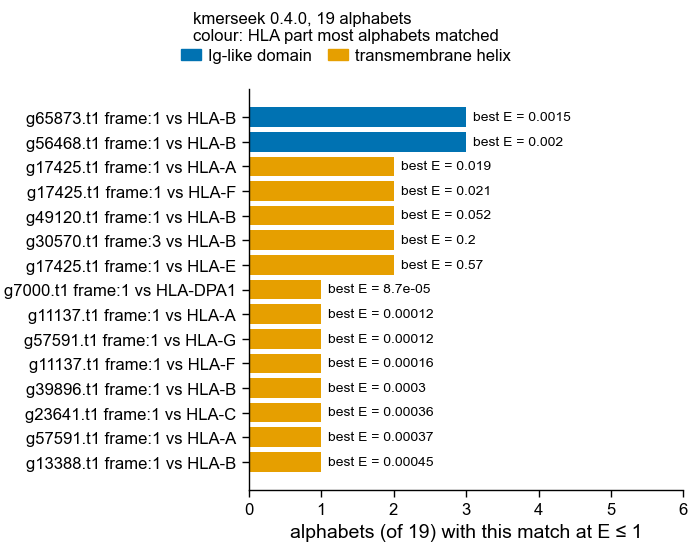

In [10]:
show = shared.head(15)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
labels = [f"{q} vs {g}" for q, g in zip(show["query_name"], show["human_gene"])]
ax.barh(range(len(show)), show["n_alphabets"], color=[PART_COLOUR[p] for p in show["most_common_part"]])
for i, (n, e) in enumerate(zip(show["n_alphabets"], show["best_evalue"])):
    ax.text(n + 0.1, i, f"best E = {e:.2g}", va="center", fontsize=5)
ax.set_yticks(range(len(show)), labels)
ax.invert_yaxis()
ax.set_xlim(0, max(show["n_alphabets"].max() + 3, 4))
ax.set_xlabel("alphabets (of 19) with this match at E ≤ 1")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=PART_COLOUR[p], label=p) for p in dict.fromkeys(show["most_common_part"])],
           loc="outside upper center", ncol=2,
           title="kmerseek 0.4.0, 19 alphabets\ncolour: HLA part most alphabets matched")
pf.save(fig, FIG_DIR / "233d_hla_matches_shared_by_alphabets_kmerseek_botryllus_vs_gencode")
plt.show()

## 4. The strongest matches to well-known immune families, per alphabet

Genes from the hand-picked family list of notebook 232 (HLA, antigen processing, Toll-like
and NOD-like receptors, complement, cytokines and receptors, interferons, TNF family,
NF-κB, IRF, TRAF, JAK/STAT, lymphocyte kinases, CD antigens, KIR/LILR, Fc receptors,
immunoglobulin and T-cell receptor genes, RAG, AIRE). Shown: every such gene with E ≤ 0.001
in at least one alphabet.

In [11]:
known = immune.filter(pl.col("human_gene").str.contains(KNOWN_IMMUNE_FAMILY_PATTERN))
best_known = known.group_by("human_gene", "alphabet").agg(pl.col("region_evalue").min().alias("best_evalue"))
strong_genes = (best_known.filter(pl.col("best_evalue") <= STRICT_EVALUE).group_by("human_gene")
                .agg(pl.col("best_evalue").min().alias("best_any"), pl.len().alias("n_alphabets_strict"))
                .sort("best_any"))
table = (best_known.filter(pl.col("human_gene").is_in(strong_genes["human_gene"]))
         .pivot(on="alphabet", index="human_gene", values="best_evalue")
         .join(strong_genes, on="human_gene").sort("best_any"))
table = table.select("human_gene", "best_any", "n_alphabets_strict", *[a for a in ALPHABETS if a in table.columns])
table.write_csv(OUT_DIR / "233_best_evalue_known_immune_genes_by_alphabet.csv")
print(f"{strong_genes.height} well-known immune genes with E <= {STRICT_EVALUE} in at least one alphabet")
print(table.select("human_gene", "best_any", "n_alphabets_strict"))

52 well-known immune genes with E <= 0.001 in at least one alphabet
shape: (52, 3)
┌─────────────────┬────────────┬────────────────────┐
│ human_gene      ┆ best_any   ┆ n_alphabets_strict │
│ ---             ┆ ---        ┆ ---                │
│ str             ┆ f64        ┆ u32                │
╞═════════════════╪════════════╪════════════════════╡
│ PSMB8           ┆ 7.6772e-46 ┆ 12                 │
│ PSMB10          ┆ 1.2629e-23 ┆ 11                 │
│ TRAF3           ┆ 1.4234e-23 ┆ 9                  │
│ SYK             ┆ 1.0929e-22 ┆ 11                 │
│ LCK             ┆ 1.1837e-22 ┆ 13                 │
│ NFKB1           ┆ 3.9544e-18 ┆ 8                  │
│ PSMB9           ┆ 8.5795e-16 ┆ 8                  │
│ BTK             ┆ 1.0018e-14 ┆ 8                  │
│ TRAF2           ┆ 1.4060e-13 ┆ 8                  │
│ ZAP70           ┆ 3.1121e-13 ┆ 12                 │
│ JAK3            ┆ 4.3319e-13 ┆ 7                  │
│ RELA            ┆ 2.4721e-12 ┆ 8                  │

/var/folders/rl/81r400y52z38l8_kwn4g1xdc0000gn/T/ipykernel_65076/787162188.py:6: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  table = (best_known.filter(pl.col("human_gene").is_in(strong_genes["human_gene"]))


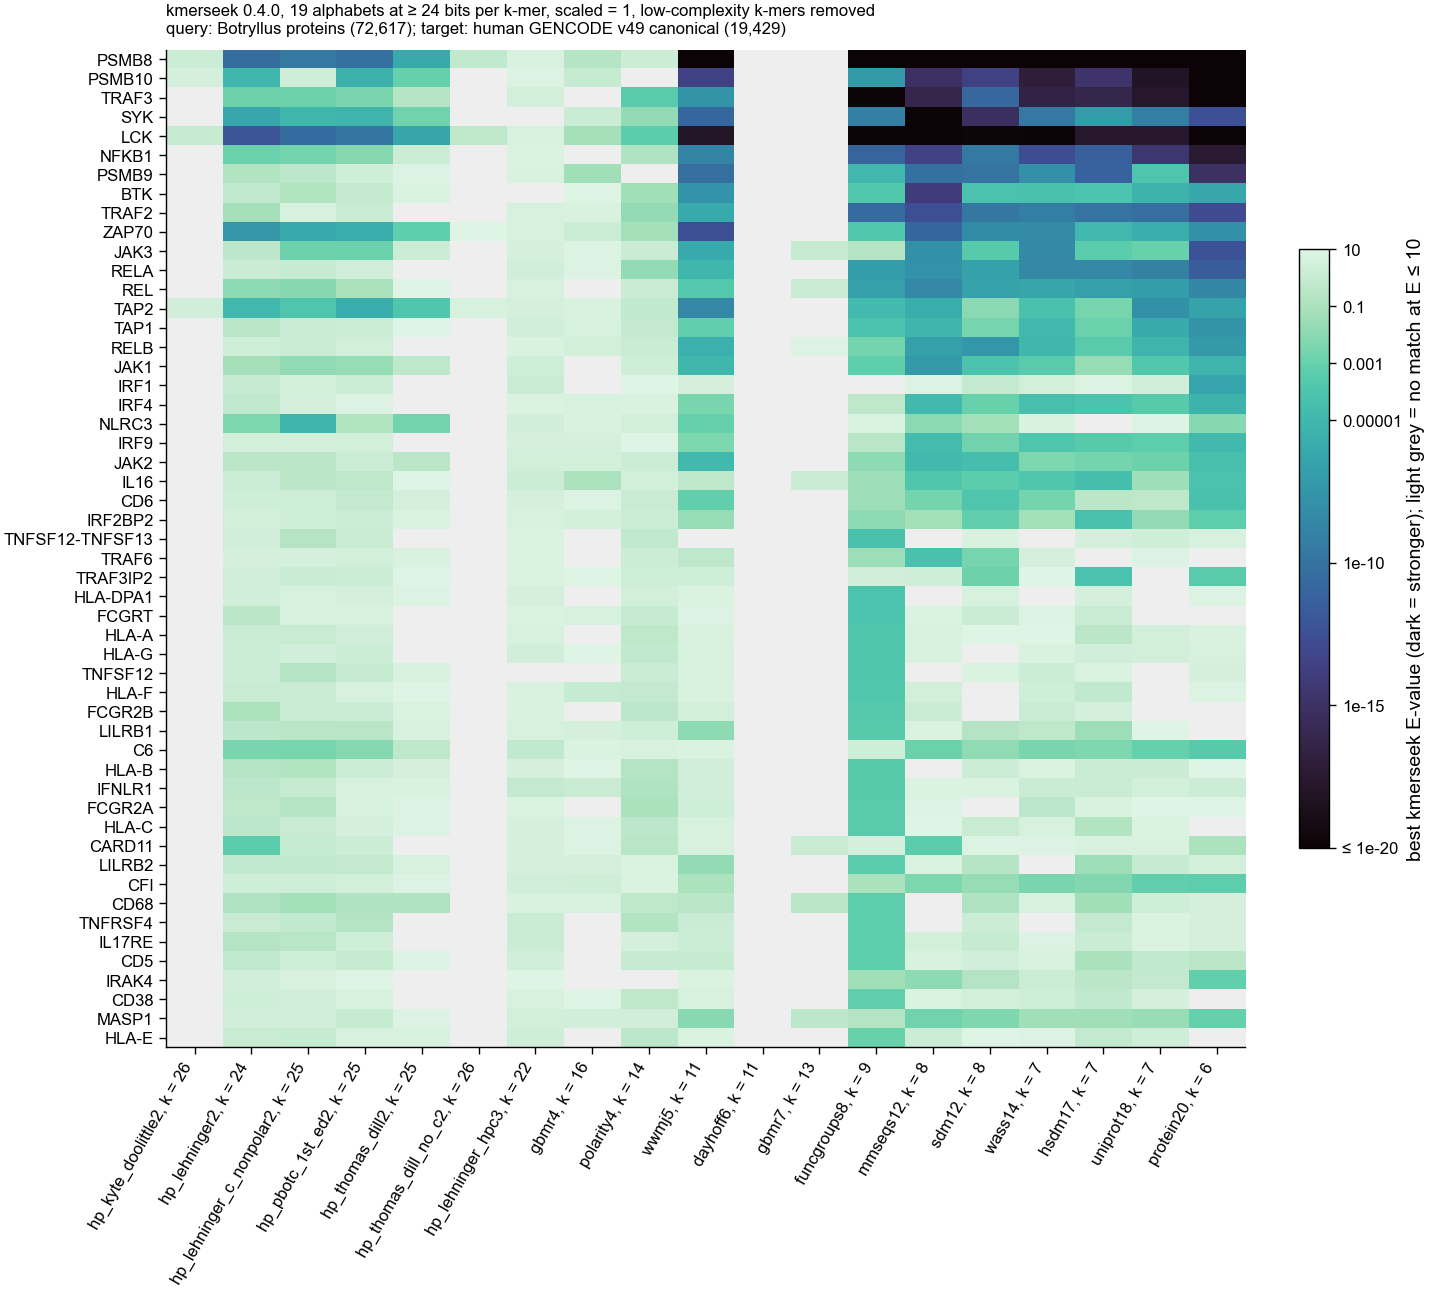

In [12]:
genes = table["human_gene"].to_list()
grid = np.full((len(genes), len(ALPHABETS)), np.nan)
for i, g in enumerate(genes):
    row = table.filter(pl.col("human_gene") == g).row(0, named=True)
    for j, a in enumerate(ALPHABETS):
        if a in row and row[a] is not None:
            grid[i, j] = np.log10(max(row[a], 1e-50))
cmap = plt.get_cmap("mako").copy()
cmap.set_bad("#eeeeee")
fig, ax = pf.figure(pf.TWO_COLUMN_MM, min(165, max(40, 30 + 2.6 * len(genes))))
FLOOR = -20  # stronger than 1e-20 all get the darkest colour, so the weaker cells stay readable
im = ax.imshow(np.ma.masked_invalid(np.clip(grid, FLOOR, None)), aspect="auto", cmap=cmap, vmin=FLOOR, vmax=1)
ax.set_xticks(range(len(ALPHABETS)), [LABEL_OF[a] for a in ALPHABETS], rotation=60, ha="right")
ax.set_yticks(range(len(genes)), genes)
cbar = fig.colorbar(im, ax=ax, shrink=0.6)
cbar.set_ticks([-20, -15, -10, -5, -3, -1, 1],
               labels=["≤ 1e-20", "1e-15", "1e-10", "0.00001", "0.001", "0.1", "10"])
cbar.set_label("best kmerseek E-value (dark = stronger); light grey = no match at E ≤ 10")
ax.set_title(f"{TOOL_LINE}\n{QUERY_TARGET_LINE}", fontsize=6, loc="left")
pf.save(fig, FIG_DIR / "233e_best_evalue_known_immune_genes_by_alphabet_kmerseek_botryllus")
plt.show()

## 5. Immune matches kmerseek did not extend (E = inf)

Summarised on Sherlock per alphabet: matches, Botryllus proteins and human immune genes, and
every unextended match to an HLA gene. With no E-value, the only measure of strength is
`region_tail_probability`, the chance of this many shared k-mers in the region. kmerseek
0.4.0 writes it uncorrected, and each alphabet makes 72,617 × 19,429 ≈ 1.4 billion
protein-pair comparisons, so a match counts here only below 0.05 / 1.4 billion ≈ 3.5e-11
(Bonferroni). The residues of the strongest ones are printed so they can be judged by eye.

In [13]:
inf_rows, inf_hla = [], []
for a in ALPHABETS:
    stem = RUN_DIR / "immune" / f"{tag(a)}.immune.evalue_inf"
    t = pl.read_csv(f"{stem}.totals.tsv", separator="\t").row(0, named=True)
    h = pl.read_csv(f"{stem}.hla.csv.gz", infer_schema_length=10_000,
                    schema_overrides={"region_evalue": pl.Float64, "region_tail_probability": pl.Float64})
    inf_rows.append({"alphabet": a, **t, "n_hla_matches": len(h),
                     "n_hla_botryllus_proteins": h["query_name"].n_unique() if len(h) else 0})
    if len(h):
        inf_hla.append(with_gene_columns(h.select(COLUMNS)).with_columns(pl.lit(a).alias("alphabet")))
inf_totals = pl.DataFrame(inf_rows)
inf_totals.write_csv(OUT_DIR / "233_immune_matches_not_extended_totals_19_alphabets.csv")
print(inf_totals)
inf_hla = pl.concat(inf_hla) if inf_hla else None
if inf_hla is not None:
    inf_hla = hla_parts.add_columns(inf_hla) if set(inf_hla["human_gene"]) <= set(hla_parts.same_length) else inf_hla
    threshold = 0.05 / N_PAIRS
    # only the matches that pass the corrected threshold are committed; all 145 thousand are in RUN_DIR
    (inf_hla.filter(pl.col("region_tail_probability") < threshold).sort("region_tail_probability")
     .write_csv(OUT_DIR / "233_hla_matches_not_extended_below_corrected_p_19_alphabets.csv"))
    inf_hla_counts = (inf_hla.group_by("alphabet")
                      .agg(pl.len().alias("n_hla_matches"),
                           pl.col("query_name").n_unique().alias("n_botryllus_proteins"),
                           (pl.col("region_tail_probability") < threshold).sum().alias("n_below_corrected_0.05"),
                           (pl.col("region_tail_probability") == 0).sum().alias("n_p_exactly_0"))
                      .sort("n_hla_matches", descending=True))
    print(f"\nUnextended HLA matches per alphabet; corrected threshold 0.05 / {N_PAIRS:,} pairs = {threshold:.2g}")
    print(inf_hla_counts)
    print("\nThe 6 with the most shared k-mers among those below the threshold, in residues:")
    top = (inf_hla.filter(pl.col("region_tail_probability") < threshold)
           .sort("region_n_shared_kmers", "region_tail_probability", descending=[True, False]).head(6))
    for r in top.iter_rows(named=True):
        print(f"{r['alphabet']:<20} {r['query_name']:<18} vs {r['human_gene']:<9} p = {r['region_tail_probability']:.2g}, "
              f"{r['region_n_shared_kmers']} shared k-mers ({r['hla_part_matched']})")
        print(f"  Botryllus {r['region_subseq'][:80]}")
        print(f"  human     {r['target_subseq'][:80]}")

shape: (19, 6)
┌──────────────────────────┬───────────┬──────────────────────┬───────────────┬───────────────┬──────────────────────────┐
│ alphabet                 ┆ n_matches ┆ n_botryllus_proteins ┆ n_human_genes ┆ n_hla_matches ┆ n_hla_botryllus_proteins │
│ ---                      ┆ ---       ┆ ---                  ┆ ---           ┆ ---           ┆ ---                      │
│ str                      ┆ i64       ┆ i64                  ┆ i64           ┆ i64           ┆ i64                      │
╞══════════════════════════╪═══════════╪══════════════════════╪═══════════════╪═══════════════╪══════════════════════════╡
│ hp_kyte_doolittle2       ┆ 233131    ┆ 6607                 ┆ 534           ┆ 54            ┆ 39                       │
│ hp_lehninger2            ┆ 115       ┆ 21                   ┆ 10            ┆ 0             ┆ 0                        │
│ hp_lehninger_c_nonpolar2 ┆ 55        ┆ 19                   ┆ 11            ┆ 0             ┆ 0                        │
│

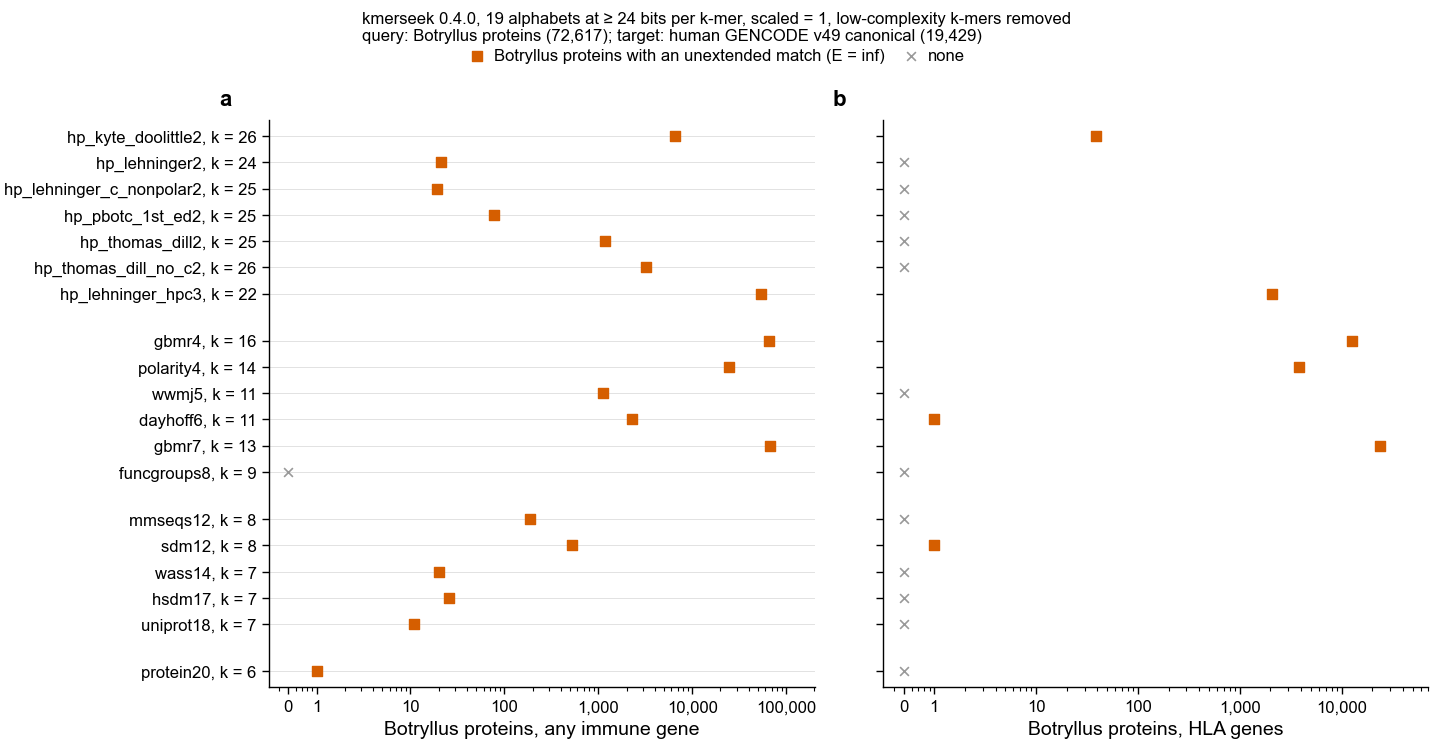

In [14]:
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for ax, col in [(ax_a, "n_botryllus_proteins"), (ax_b, "n_hla_botryllus_proteins")]:
    n = inf_totals[col].to_numpy()
    ys = [Y_OF[a] for a in inf_totals["alphabet"]]
    ax.scatter(np.where(n > 0, n, np.nan), ys, color=pf.OKABE_ITO["vermillion"], marker="s", s=12, zorder=3,
               label="Botryllus proteins with an unextended match (E = inf)")
    ax.scatter(np.where(n == 0, ZERO_X, np.nan), ys, color=pf.GREY, marker="x", s=10, linewidths=0.6,
               label="none")
    ax.set_xscale("log")
    ax.set_xlim(ZERO_X / 1.6, max(n.max(), 1) * 3)
    ticks = [t for t in [1, 10, 100, 1_000, 10_000, 100_000] if t <= max(n.max(), 1) * 3]
    ax.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
ax_a.set_xlabel("Botryllus proteins, any immune gene")
ax_b.set_xlabel("Botryllus proteins, HLA genes")
alphabet_axis(ax_a)
pf.shared_legend(fig, ncol=2, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip((ax_a, ax_b), "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "233f_immune_matches_not_extended_kmerseek_botryllus_vs_gencode_19_alphabets")
plt.show()

## Summary and conclusions

Tool for every number below: kmerseek 0.4.0, 19 alphabets each at the k that carries at least
24 bits per k-mer, scaled = 1, low-complexity k-mers removed. Query: 72,617 Botryllus proteins.
Target: 19,429 human GENCODE v49 canonical proteins.

1. **No alphabet finds an MHC-like candidate under the rule written at the top.** Across the 19
   alphabets there are 3,950 HLA matches with E ≤ 10, from 1,363 Botryllus proteins. The
   strongest match to the peptide-binding groove or the Ig-like domain, in any alphabet, is the
   one notebook 232 found: g564.t1 to the HLA-DRA Ig-like domain, E = 0.13 (hp_lehninger2,
   k = 24). No other groove or Ig-like match has E below 0.17.

2. **Only funcgroups8 (k = 9) gives HLA matches below E = 0.001, and all 14 are to the HLA
   transmembrane helix.** They come from 9 Botryllus proteins, for example g7000.t1
   (`TSDTGLIIGVVAALLGIAALASLAV`) against the HLA-DPA1 helix (`TTETVLCALGLVLGLVGIIVGTVLI`),
   E = 0.000087. Of funcgroups8's 2,710 HLA matches, 2,645 cover the helix. The same alphabet
   gives HLA, Fc receptor and LILR genes, all single-pass membrane proteins, near-identical
   best E-values around 0.0001 (figure 233e). funcgroups8 is also the one alphabet with no
   measured extension penalty (it runs on the fallback 2 / 8), so its E-values are the least
   trustworthy of the 19.

3. **Five alphabets leave almost every match unextended, so they say little either way.** For
   dayhoff6 (k = 11), gbmr7 (k = 13), gbmr4 (k = 16), hp_kyte_doolittle2 (k = 26) and
   hp_thomas_dill_no_c2 (k = 26), over 99.7% of kept matches have E = inf; dayhoff6 has 41
   matches with a finite E-value out of 5.1 million. "No HLA match at E ≤ 10" in those
   alphabets means no E-value was computed, not that nothing matched.

4. **The unextended HLA matches look like shared composition, not shared ancestry.** gbmr7,
   gbmr4, polarity4 and hp_lehninger_hpc3 have 76,412, 31,044, 33,977 and 3,751 unextended
   HLA matches. 1,535 of them pass a k-mer p-value corrected for the 1.4 billion protein pairs
   each alphabet compares, and 204 have p = 0 exactly. The strongest pair a charged,
   repetitive Botryllus stretch (`REKRRIQEQLRRIKRNQEKEK`) with the HLA α2 helix: in gbmr4 every
   polar residue falls into one class, so any polar run matches any other. A p-value of exactly
   0 for residues this unlike each other points to a limit of kmerseek's unextended-region
   statistic, not to homology.

5. **Well-known immune genes are found strongly by many alphabets, but through domains every
   cell has.** PSMB8 (best E = 8e-46, 12 alphabets at E ≤ 0.001), LCK (13 alphabets), ZAP70
   (12), SYK (11), PSMB10 (11) and TAP2 (10) are kinase, proteasome and ABC-transporter domains.
   The NF-κB family (NFKB1, RELA, REL, RELB) is found by 7 or 8 alphabets each, which fits a
   Rel-family protein in Botryllus. The alphabets with 12 or more classes and protein20 find
   these best; most HP alphabets find them less strongly.

**Verdict against the rule written at the top:** none of the 19 alphabets gives a Botryllus
protein matching an HLA groove or Ig-like domain at E ≤ 0.001, so no protein goes forward as an
MHC-like candidate from kmerseek. The "no HLA match" of notebook 232 does not depend on the
alphabet. The one alphabet with strong HLA matches (funcgroups8) finds membrane helices.

**What this does not settle.** Five alphabets have almost no E-values, so their silence is not
evidence; a kmerseek follow-up should find why so many of their matches are not extended (the
share ranges from 0% for funcgroups8 to 99.999% for dayhoff6 at similar bits per k-mer), and why
unrelated residues can give a region p-value of 0. A search for an MHC fold that has lost
sequence similarity needs structure comparison (Foldseek against HLA structures), not k-mers.

Output tables, in `notebooks/233_outputs/`: runs per alphabet, immune and HLA counts per E-value
cut-off, every HLA match with E ≤ 10 (with residues and the HLA part), HLA matches shared by
alphabets, best E-value per well-known immune gene per alphabet, the unextended totals, and
the 1,535 unextended HLA matches that pass the corrected p-value (all 145,241 are in
`~/data/botryllus/kmerseek-0.4-alphabets/` and on Sherlock). Figures, in `figures/233/`: `233a` runs, `233b` counts per alphabet, `233c` every
HLA match, `233d` matches shared by alphabets, `233e` well-known immune genes, `233f` unextended
matches.